# 02 - Models 1-4: Logistic Regression, Naïve Bayes, KNN & SVM
This notebook develops and evaluates the Logistic Regression, Naive Bayes, K-Nearest Neighbors and Support Vector Machine models, with F1 for the positive class (`Revenue=True`) as the primary metric.

It reuses the team's shared validation setup (same predictors, folds, scorer, metrics) so every result can be compared directly with the rest of the team's models. The shared preprocessor is also reused for Logistic Regression, KNN, and SVM, while Naive Bayes uses model-specific preprocessing.

**Rimma's Workflow/Steps:**
1. Rebuild the shared preprocessing and validation setup from 01_data_preprocessing; model-specific preprocessors for Naive Bayes.
2. Evaluate baseline models (Section 3).
3. Tune each model with `GridSearchCV` using the same folds and scorer (Section 4).
4. Compare and evaluate all baseline and tuned models (Section 5).

> The test file (`challenge2_test.csv`) is not used anywhere in this notebook.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, KBinsDiscretizer, PowerTransformer,
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    make_scorer, ConfusionMatrixDisplay,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, GridSearchCV, cross_validate, cross_val_predict,
)

RANDOM_STATE = 42

## 1. Preprocessing and validation setup
Same predictors, preprocessor, hashed groups, StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), and F1 scorer as `01_data_preprocessing.ipynb`.

In [2]:
train_df = pd.read_csv("challenge2_train.csv")

X = train_df.drop(columns=["ID", "Revenue"])
y = train_df["Revenue"]

categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
numeric_features = X.columns.difference(
    categorical_features, sort=False
).tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features,
    ),
])

# Keep sessions with identical features in the same fold.
groups = pd.util.hash_pandas_object(X, index=False)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv = list(splitter.split(X, y, groups=groups))

f1_positive = make_scorer(f1_score, pos_label=True, zero_division=0)

print("Feature matrix:", X.shape, "| Purchase rate:", round(100 * y.mean(), 2), "%")
print("Validation fold sizes:", [len(v) for _, v in cv])

Feature matrix: (9247, 17) | Purchase rate: 15.48 %
Validation fold sizes: [1850, 1849, 1850, 1849, 1849]


### Naive Bayes model-specific preprocessing
Bernoulli NB expects binary (0/1) features. Our shared preprocessor also produces standardized numeric
columns, which are not binary. Gaussian NB assumes normally distributed features, but the numeric columns are right-skewed, and the one-hot columns are not continuous values. So model-specific preprocessors are used for NB, but the rest of the setup is still shared so the results remain comparable.

In [3]:
# Model-specific preprocessing for Naive Bayes
# Bernoulli NB: binned numeric features + the categorical branch of the shared preprocessor
categorical_branch = [t for t in preprocessor.transformers if t[0] == "categorical"]

bnb_preprocessor = ColumnTransformer(
    [(
        "numeric_bins",
        KBinsDiscretizer(n_bins=5, encode="onehot-dense",
                         strategy="quantile", subsample=None),
        numeric_features,
    )] + categorical_branch
)

# Gaussian NB: Yeo-Johnson transformed numeric features only (ExitRates dropped, r ~ 0.91 with BounceRates)
gnb_numeric_features = [c for c in numeric_features if c != "ExitRates"]

gnb_preprocessor = ColumnTransformer([
    ("numeric", PowerTransformer(method="yeo-johnson", standardize=True),
     gnb_numeric_features),
])


## 2. Evaluation helper

All models are scored with the same folds, and F1 for the positive class as the primary metric.

Precision, recall, ROC AUC, average precision and accuracy are additionally reported to give context
(accuracy alone is misleading since ~85% of sessions are non-purchases).
Training scores are included to spot over/underfitting.

In [4]:
scoring = {
    "f1": f1_positive,
    "precision": make_scorer(precision_score, pos_label=True, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=True, zero_division=0),
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
    "accuracy": "accuracy",
}

def evaluate(name, estimator):
    """Cross-validate on the shared folds; return one summary row."""
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    row = {"Model": name}
    for m in scoring:
        row[f"Val {m}"] = res[f"test_{m}"].mean()
    row["Val F1 std"] = res["test_f1"].std()
    row["Train F1"] = res["train_f1"].mean()
    return row

## 3. Baseline models
### 3.1 Logistic Regression
Standard baseline with no class weighting and default regularisation.

In [5]:
log_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

results = [evaluate("Logistic Regression (baseline)", log_base)]

### 3.2 Naive Bayes
Two variants are evaluated with model-specific preprocessors and default settings:

* **Bernoulli NB (binned numeric + categorical)** - the numeric features are binned and one-hot encoded, the categorical branch of the shared preprocessor is reused (same encoder and column list)
* **Gaussian NB (Yeo-Johnson numeric)** - a yeo-johnson PowerTransformer reduces the skew of numeric features, so a normal distribution is a closer fit. The one-hot columns are left out, and `ExitRates` is dropped because it's strongly correlated with `BounceRates` (NB assumes features are conditionally independent given the class).


In [6]:
# Naive Bayes baselines: model-specific preprocessors are defined in Section 1
bnb_base = Pipeline([
    ("preprocess", bnb_preprocessor),
    ("clf", BernoulliNB()),
])

gnb_base = Pipeline([
    ("preprocess", gnb_preprocessor),
    ("clf", GaussianNB()),
])

results.append(evaluate("Bernoulli NB (baseline)", bnb_base))
results.append(evaluate("Gaussian NB (baseline)", gnb_base))

### 3.3 K-Nearest Neighbors
KNN predicts by voting among the K closest training sessions, so the distances must be meaningful.
That is why the shared preprocessor standardizes the numeric features (so large-scale columns such as the duration
variables don't dominate the distance) and one-hot encodes the categorical ones.

The baseline uses `K=5`, uniform voting, and Euclidean distance.

In [7]:
knn_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="euclidean")),
])

results.append(evaluate("KNN (baseline, K=5)", knn_base))

### 3.4 Support Vector Machine
SVMs depend on distances between observations, so feature scaling in the shared preprocessor matters.
Two baseline kernels are evaluated, both with `C=1.0` and `class_weight="balanced"`:

* **Linear SVM**
* **RBF SVM** (`gamma="scale"`)

Balanced weights penalize mistakes on the rarer Revenue=True class more, which usually raises recall at some cost in precision and often helps F1 on imbalanced data.

In [8]:
svm_linear_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(kernel="linear", C=1.0, class_weight="balanced")),
])
svm_rbf_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")),
])

results.append(evaluate("Linear SVM (baseline)", svm_linear_base))
results.append(evaluate("RBF SVM (baseline)", svm_rbf_base))

### Baseline results

In [9]:
baseline_table = pd.DataFrame(results).set_index("Model")
baseline_table.round(3)

,Val f1,Val precision,Val recall,Val roc_auc,Val avg_precision,Val accuracy,Val F1 std,Train F1
Model,,,,,,,,
Logistic Regression (baseline),0.515,0.744,0.394,0.894,0.649,0.885,0.007,0.525
Bernoulli NB (baseline),0.608,0.507,0.760,0.877,0.528,0.848,0.018,0.610
Gaussian NB (baseline),0.598,0.489,0.771,0.859,0.479,0.840,0.014,0.599
"KNN (baseline, K=5)",0.478,0.659,0.376,0.792,0.489,0.873,0.024,0.604
Linear SVM (baseline),0.663,0.589,0.760,0.912,0.671,0.881,0.017,0.667
RBF SVM (baseline),0.646,0.560,0.763,0.909,0.664,0.870,0.016,0.717


## 4. Hyperparameter tuning (Grid Search)

`GridSearchCV` uses the same `cv` folds and `f1_positive` scorer as the baselines, so the tuned and baseline models are compared fairly.

* **Logistic Regression:** `C`, penalty type, and `class_weight`. With only ~15% positives,
  `class_weight="balanced"` makes the model pay more attention to purchases and typically raises recall (and often F1)
  at the default 0.5 decision threshold.
* **Bernoulli NB:** smoothing `alpha`, and the class prior (`fit_prior`).
* **Gaussian NB:** `var_smoothing`, and the class `priors`.
* **KNN:** `K` (small K is flexible/noisy, large K is smooth), `uniform` vs `distance`-weighted voting, and distance metric.
* **SVM:** kernel, `C`, `class_weight`, and `gamma` for the RBF kernel.
  `C` and `gamma` interact, so they are searched jointly (the default `gamma="scale"` is about 0.06 on this data, so the grid also includes smaller values).

Note: the best CV score is slightly optimistic because the same folds are used to choose the
configuration and to report it. Differences of a few thousandths should be treated as noise.

In [10]:
def run_grid(name, pipe, param_grid):
    gs = GridSearchCV(pipe, param_grid, scoring=f1_positive, cv=cv,
                      n_jobs=-1, refit=True)
    gs.fit(X, y)
    print(f"{name}\n  best params: {gs.best_params_}\n  best CV F1:  {gs.best_score_:.4f}\n")
    return gs

In [11]:
grid_lr = run_grid(
    "Logistic Regression",
    log_base,
    {
        "clf__solver": ["liblinear"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "clf__class_weight": [None, "balanced", {False: 1, True: 2}, {False: 1, True: 3}],
    },
)

best_coef = grid_lr.best_estimator_.named_steps["clf"].coef_[0]
kept = grid_lr.best_estimator_.named_steps["preprocess"].get_feature_names_out()[best_coef != 0]
print(f"Non-zero coefficients: {len(kept)} of {len(best_coef)} -> {list(kept)}")

Logistic Regression
  best params: {'clf__C': 0.001, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
  best CV F1:  0.6687

Non-zero coefficients: 1 of 75 -> ['numeric__PageValues']


In [12]:
grid_bnb = run_grid(
    "Bernoulli NB",
    bnb_base,
    {
        "clf__alpha": [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0],
        "clf__fit_prior": [True, False],
    },
)

grid_gnb = run_grid(
    "Gaussian NB",
    gnb_base,
    {
        "clf__var_smoothing": np.logspace(-11, 1, 13),
        "clf__priors": [None, [0.5, 0.5], [0.7, 0.3]],
    },
)

Bernoulli NB
  best params: {'clf__alpha': 50.0, 'clf__fit_prior': True}
  best CV F1:  0.6137

Gaussian NB
  best params: {'clf__priors': None, 'clf__var_smoothing': np.float64(0.1)}
  best CV F1:  0.6004



In [13]:
grid_knn = run_grid(
    "K-Nearest Neighbors",
    knn_base,
    {
        "clf__n_neighbors": [1, 3, 5, 11, 21, 31, 51, 71],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan"],
    },
)

K-Nearest Neighbors
  best params: {'clf__metric': 'euclidean', 'clf__n_neighbors': 3, 'clf__weights': 'uniform'}
  best CV F1:  0.4930



In [14]:
grid_svm = run_grid(
    "Support Vector Machine",
    Pipeline([("preprocess", preprocessor), ("clf", SVC())]),
    [
        {"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1.0],
         "clf__class_weight": [None, "balanced"]},
        {"clf__kernel": ["rbf"], "clf__C": [0.1, 1.0, 10.0],
         "clf__gamma": ["scale", 0.003, 0.01, 0.03],
         "clf__class_weight": [None, "balanced"]},
    ],
)

Support Vector Machine
  best params: {'clf__C': 10.0, 'clf__class_weight': 'balanced', 'clf__gamma': 0.003, 'clf__kernel': 'rbf'}
  best CV F1:  0.6671



## 5. Compare all models
### 5.1 Comparison table
Tuned models are re-evaluated with `evaluate()` (same folds, same metrics) so every row in the table is computed the same way.
The table covers the baseline and tuned models, sorted by validation F1.

In [15]:
tuned = {
    "Logistic Regression (tuned)": grid_lr.best_estimator_,
    "Bernoulli NB (tuned)": grid_bnb.best_estimator_,
    "Gaussian NB (tuned)": grid_gnb.best_estimator_,
    "KNN (tuned)": grid_knn.best_estimator_,
    "SVM (tuned)": grid_svm.best_estimator_,
}
for name, est in tuned.items():
    results.append(evaluate(name, clone(est)))

comparison = (pd.DataFrame(results).set_index("Model")
              .sort_values("Val f1", ascending=False))
comparison.round(3)

,Val f1,Val precision,Val recall,Val roc_auc,Val avg_precision,Val accuracy,Val F1 std,Train F1
Model,,,,,,,,
Logistic Regression (tuned),0.669,0.627,0.716,0.870,0.637,0.890,0.006,0.669
SVM (tuned),0.667,0.590,0.767,0.914,0.688,0.881,0.012,0.675
Linear SVM (baseline),0.663,0.589,0.760,0.912,0.671,0.881,0.017,0.667
RBF SVM (baseline),0.646,0.560,0.763,0.909,0.664,0.870,0.016,0.717
Bernoulli NB (tuned),0.614,0.552,0.690,0.877,0.525,0.866,0.025,0.617
Bernoulli NB (baseline),0.608,0.507,0.760,0.877,0.528,0.848,0.018,0.610
Gaussian NB (tuned),0.600,0.495,0.762,0.862,0.478,0.843,0.011,0.601
Gaussian NB (baseline),0.598,0.489,0.771,0.859,0.479,0.840,0.014,0.599
Logistic Regression (baseline),0.515,0.744,0.394,0.894,0.649,0.885,0.007,0.525


### 5.2 Overfitting / underfitting check
A large gap between `Train F1` and `Val f1` indicates overfitting; low values on both indicate underfitting.

In [16]:
gap = comparison[["Train F1", "Val f1"]].copy()
gap["Gap (train - val)"] = gap["Train F1"] - gap["Val f1"]
gap.round(3)

,Train F1,Val f1,Gap (train - val)
Model,,,
Logistic Regression (tuned),0.669,0.669,0.000
SVM (tuned),0.675,0.667,0.008
Linear SVM (baseline),0.667,0.663,0.004
RBF SVM (baseline),0.717,0.646,0.071
Bernoulli NB (tuned),0.617,0.614,0.003
Bernoulli NB (baseline),0.610,0.608,0.002
Gaussian NB (tuned),0.601,0.600,0.001
Gaussian NB (baseline),0.599,0.598,0.001
Logistic Regression (baseline),0.525,0.515,0.010


### 5.3 Confusion matrices (out-of-fold predictions, tuned models)
Each prediction comes from a model that did not see that row during training (same shared folds).

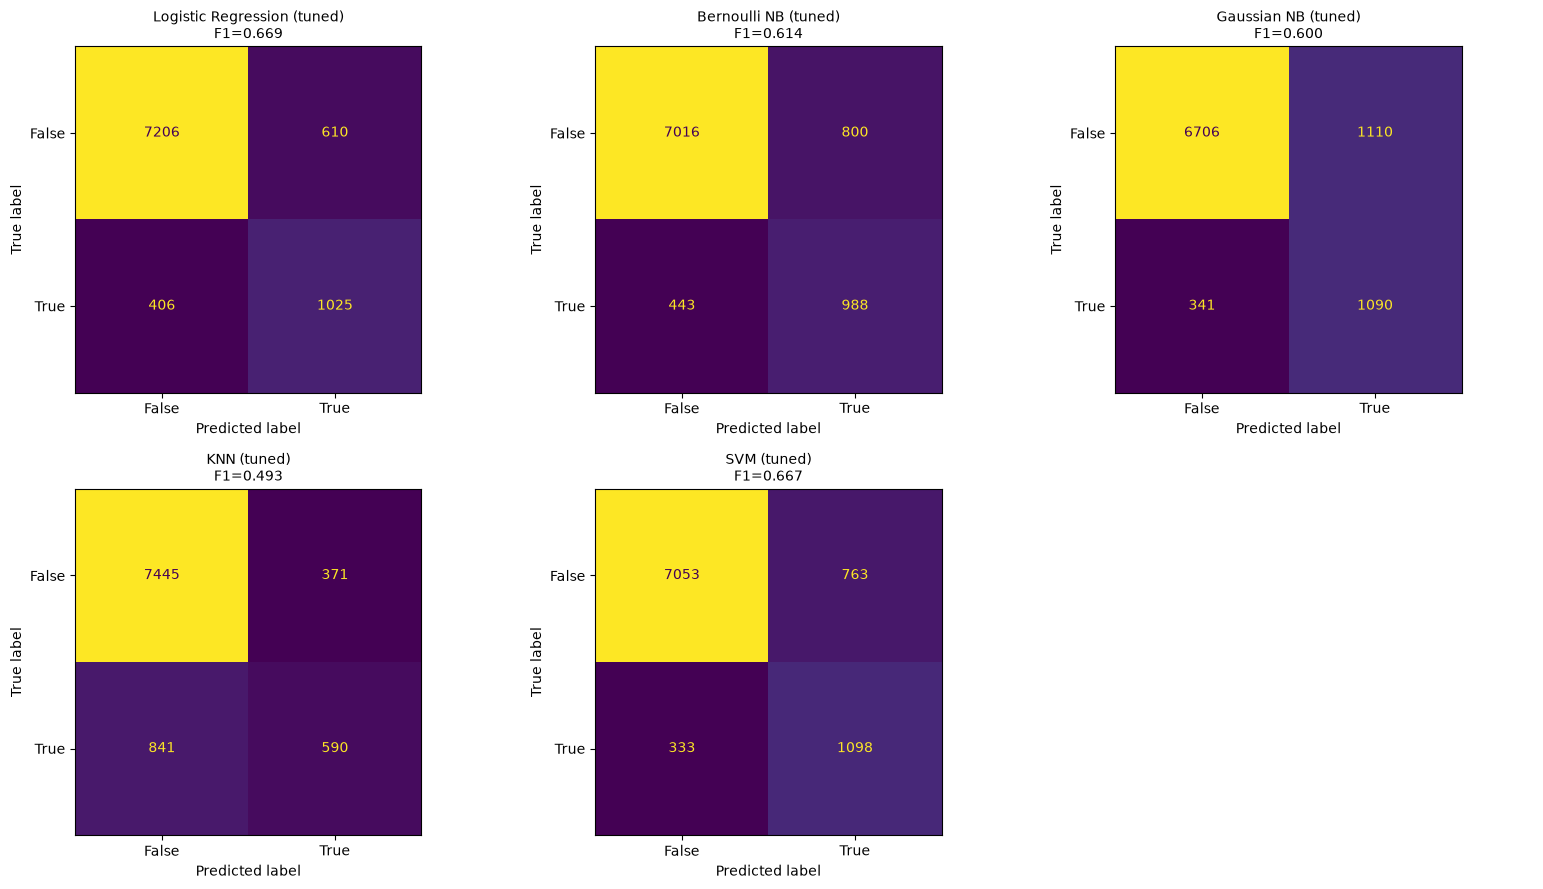

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for ax, (name, est) in zip(axes, tuned.items()):
    oof = cross_val_predict(clone(est), X, y, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y, oof, ax=ax, colorbar=False)
    ax.set_title(f"{name}\nF1={f1_score(y, oof, pos_label=True):.3f}", fontsize=10)
for ax in axes[len(tuned):]:
    ax.axis("off")
plt.tight_layout()
plt.show()